# Engenharia de recursos e visualização: House Prices

Integrantes: Diogo Galrão Carvalho, Felipe Artur Macedo Lima e Luan Cavalcante Dias Rodrigues.

Objetivo: explorar os preços de venda, criar atributos, comparar sua importância em uma floresta aleatória e visualizar dados numéricos com PCA.

## 1. Configuração do ambiente e importação das bibliotecas

Resolução de caminhos a partir da raiz do repositório para assegurar execução consistente tanto via linha de comando quanto via ambiente interativo de notebooks.

In [1]:
from pathlib import Path
import json
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

# Resolução canônica de diretórios
PROJECT_ROOT = Path(".").resolve() if (Path("data").is_dir() and Path("reports").is_dir()) else Path("..").resolve()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EVIDENCE_DIR = PROJECT_ROOT / "reports" / "evidence"
FIGURES_DIR = EVIDENCE_DIR / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Configuração visual padronizada
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.titlesize"] = 12
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

## 2. Passo 1 — Carga e inspeção inicial dos dados

Carregamento do arquivo `data/raw/house_prices.csv` e inspeção do volume de dados, tipos primitivos de colunas e valores iniciais.

In [2]:
df = pd.read_csv(RAW_DIR / "house_prices.csv")
print(f"Estrutura do dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
df.info()

Estrutura do dataset carregado: 1460 linhas x 81 colunas

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  Overa

In [3]:
# Estatísticas descritivas das primeiras variáveis numéricas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


In [4]:
# Visualização dos cinco primeiros registros
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Passo 2 — Distribuição do preço de venda (SalePrice) e correlações lineares

Inspeção da variável dependente com histograma, curva KDE e boxplot para avaliar assimetria e valores extremos, acompanhada de mapa de calor das variáveis numéricas mais correlacionadas.

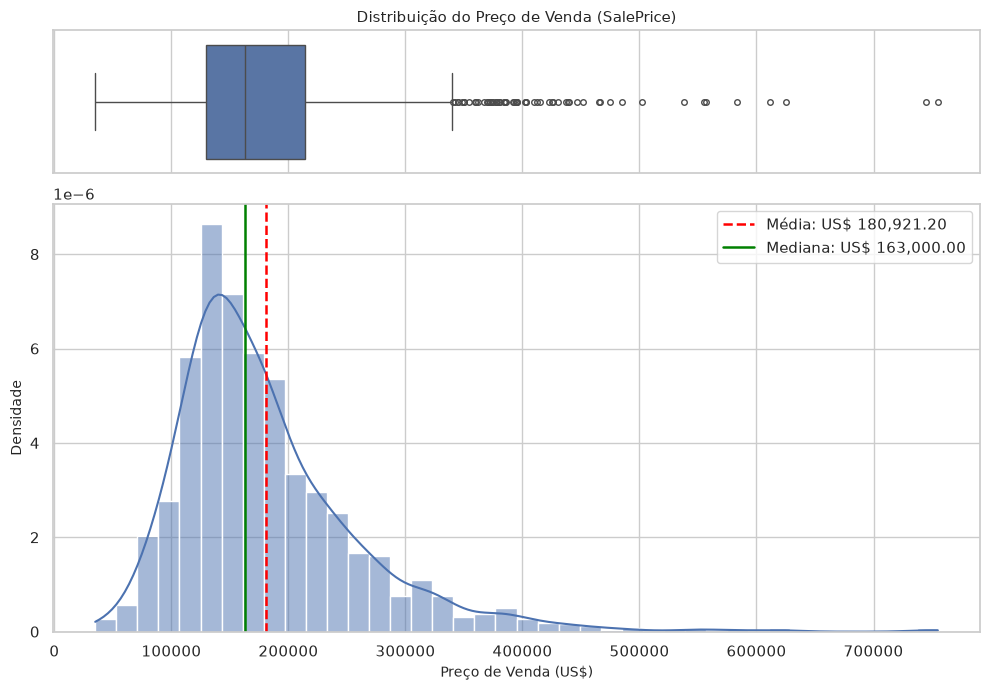

Média: US$ 180921.20
Mediana: US$ 163000.00
Desvio padrão: US$ 79442.50
Assimetria (Skewness): 1.8829
Curtose (Kurtosis): 6.5363


In [5]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [0.25, 0.75]}
)

# Boxplot horizontal superior
sns.boxplot(x=df["SalePrice"], ax=ax_box, color="#4C72B0", fliersize=4)
ax_box.set(xlabel="")
ax_box.set_title("Distribuição do Preço de Venda (SalePrice)")

# Histograma com KDE inferior
sns.histplot(df["SalePrice"], kde=True, ax=ax_hist, color="#4C72B0", bins=40, stat="density")
ax_hist.set_xlabel("Preço de Venda (US$)")
ax_hist.set_ylabel("Densidade")

# Marcações de média e mediana
saleprice_mean = df["SalePrice"].mean()
saleprice_median = df["SalePrice"].median()
ax_hist.axvline(saleprice_mean, color="red", linestyle="--", linewidth=1.8, label=f"Média: US$ {saleprice_mean:,.2f}")
ax_hist.axvline(saleprice_median, color="green", linestyle="-", linewidth=1.8, label=f"Mediana: US$ {saleprice_median:,.2f}")
ax_hist.legend(loc="upper right")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "house_prices_target_dist.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Média: US$ {saleprice_mean:.2f}")
print(f"Mediana: US$ {saleprice_median:.2f}")
print(f"Desvio padrão: US$ {df['SalePrice'].std():.2f}")
print(f"Assimetria (Skewness): {df['SalePrice'].skew():.4f}")
print(f"Curtose (Kurtosis): {df['SalePrice'].kurt():.4f}")

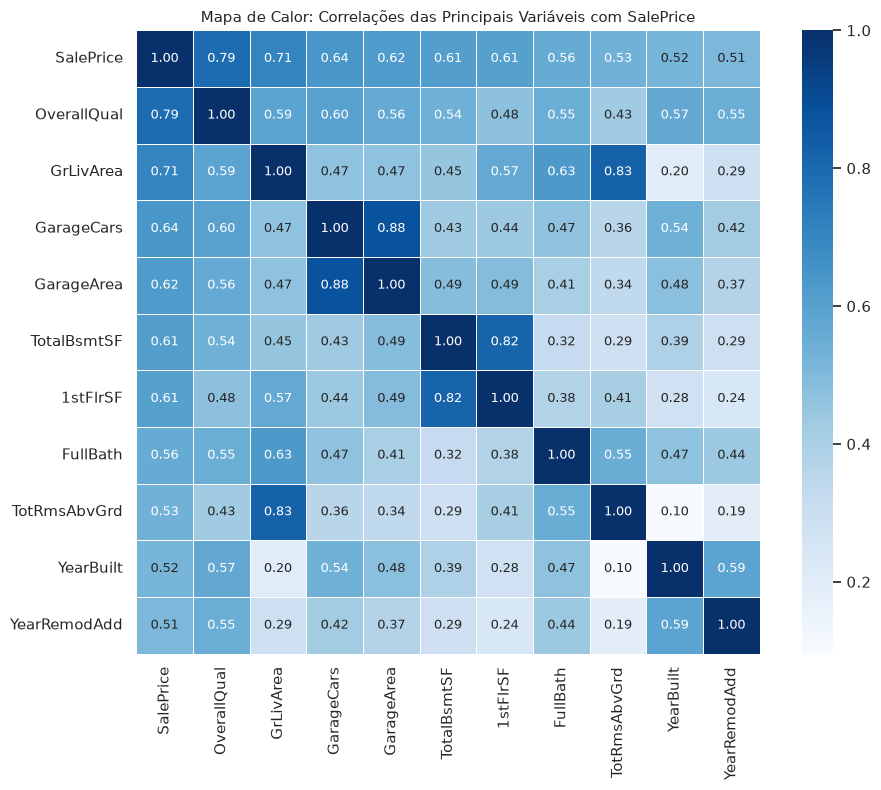

Top 10 variáveis numéricas com maior correlação positiva com SalePrice:
  - OverallQual    : +0.7910
  - GrLivArea      : +0.7086
  - GarageCars     : +0.6404
  - GarageArea     : +0.6234
  - TotalBsmtSF    : +0.6136
  - 1stFlrSF       : +0.6059
  - FullBath       : +0.5607
  - TotRmsAbvGrd   : +0.5337
  - YearBuilt      : +0.5229
  - YearRemodAdd   : +0.5071


In [6]:
# Seleção das principais variáveis numéricas por correlação de Pearson com SalePrice
num_cols = df.select_dtypes(include=[np.number]).columns
corr_series = df[num_cols].corr()["SalePrice"].sort_values(ascending=False)
top_corr_vars = corr_series.head(11).index.tolist()

corr_matrix = df[top_corr_vars].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar=True,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title("Mapa de Calor: Correlações das Principais Variáveis com SalePrice")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("Top 10 variáveis numéricas com maior correlação positiva com SalePrice:")
for col, val in corr_series.head(11).items():
    if col != "SalePrice":
        print(f"  - {col:15s}: {val:+.4f}")

## 4. Dataset e objetivo

O conjunto reúne 1.460 vendas residenciais em Ames, Iowa, entre 2006 e 2010. O arquivo tem 79 atributos explicativos, um identificador e o preço de venda. A análise investiga associações com o preço e compara atributos criados com os originais.

## 5. Distribuição e correlações

`SalePrice` tem assimetria de 1,88, mediana de US$ 163.000 e média de US$ 180.921. Entre as variáveis numéricas originais, `OverallQual` tem correlação de 0,79 com o preço e `GrLivArea`, de 0,71. Essas correlações descrevem relações lineares na amostra, sem demonstrar causalidade.

## 6. Passo 5 — Engenharia de atributos: HouseAge e TotalArea

Criação de dois atributos quantitativos contínuos derivados das variáveis originais de data e metragem:
- `HouseAge`: idade da residência no momento da venda (`YrSold - YearBuilt`).
- `TotalArea`: somatório da área do subsolo com os pavimentos habitáveis (`TotalBsmtSF + 1stFlrSF + 2ndFlrSF`).

In [7]:
# Construção dos atributos HouseAge e TotalArea
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["TotalArea"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

print("Estatísticas descritivas das novas variáveis:")
df[["HouseAge", "TotalArea"]].describe().T.round(2)

Estatísticas descritivas das novas variáveis:


,count,mean,std,min,25%,50%,75%,max
HouseAge,1460.0,36.55,30.25,0.0,8.0,35.0,54.0,136.0
TotalArea,1460.0,2567.05,821.71,334.0,2009.5,2474.0,3004.0,11752.0


## 7. Passo 6 — Engenharia de atributos: IsRemodeled

Criação de um indicador binário que sinaliza se a propriedade recebeu reforma ou acréscimo após a construção original (`YearRemodAdd != YearBuilt`).

In [8]:
# Construção do indicador binário IsRemodeled
df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)

remod_counts = df["IsRemodeled"].value_counts()
remod_pct = df["IsRemodeled"].value_counts(normalize=True) * 100

remod_summary = pd.DataFrame({
    "Contagem": remod_counts,
    "Percentual (%)": remod_pct.round(2)
}, index=[0, 1])
remod_summary.index = ["Original (0)", "Reformado (1)"]
print("Distribuição de imóveis reformados versus estado original:")
remod_summary

Distribuição de imóveis reformados versus estado original:


,Contagem,Percentual (%)
Original (0),764,52.33
Reformado (1),696,47.67


## 8. Passo 7 — Diagnóstico visual dos atributos criados

Avaliação gráfica do comportamento das novas variáveis em relação a `SalePrice`: dispersão com reta de regressão para `HouseAge` e `TotalArea`, e boxplot comparativo para `IsRemodeled`.

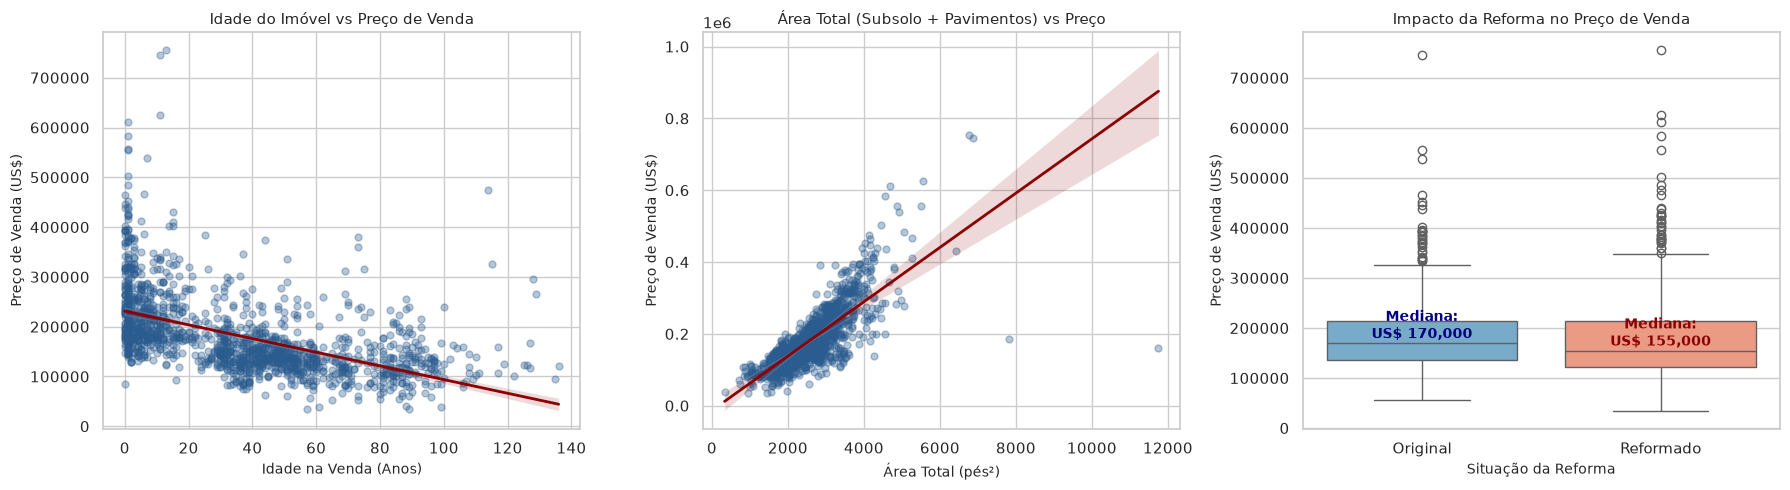

Correlação linear de HouseAge com SalePrice: -0.5234
Correlação linear de TotalArea com SalePrice: +0.7823
Mediana (Original): US$ 170,000.00 | Mediana (Reformado): US$ 155,000.00


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: HouseAge vs SalePrice
sns.regplot(
    data=df,
    x="HouseAge",
    y="SalePrice",
    ax=axes[0],
    color="#2b5c8f",
    scatter_kws={"alpha": 0.35, "s": 25},
    line_kws={"color": "darkred", "linewidth": 2},
)
axes[0].set_title("Idade do Imóvel vs Preço de Venda")
axes[0].set_xlabel("Idade na Venda (Anos)")
axes[0].set_ylabel("Preço de Venda (US$)")

# Gráfico 2: TotalArea vs SalePrice
sns.regplot(
    data=df,
    x="TotalArea",
    y="SalePrice",
    ax=axes[1],
    color="#2b5c8f",
    scatter_kws={"alpha": 0.35, "s": 25},
    line_kws={"color": "darkred", "linewidth": 2},
)
axes[1].set_title("Área Total (Subsolo + Pavimentos) vs Preço")
axes[1].set_xlabel("Área Total (pés²)")
axes[1].set_ylabel("Preço de Venda (US$)")

# Gráfico 3: IsRemodeled vs SalePrice
sns.boxplot(
    data=df,
    x="IsRemodeled",
    y="SalePrice",
    ax=axes[2],
    palette=["#6baed6", "#fc9272"],
)
axes[2].set_title("Impacto da Reforma no Preço de Venda")
axes[2].set_xlabel("Situação da Reforma")
axes[2].set_ylabel("Preço de Venda (US$)")
axes[2].set_xticklabels(["Original", "Reformado"])

# Anotação das medianas no gráfico de boxplot
mediana_orig = df[df["IsRemodeled"] == 0]["SalePrice"].median()
mediana_remod = df[df["IsRemodeled"] == 1]["SalePrice"].median()
axes[2].text(0, mediana_orig + 10000, f"Mediana:\nUS$ {mediana_orig:,.0f}", ha="center", weight="bold", color="navy")
axes[2].text(1, mediana_remod + 10000, f"Mediana:\nUS$ {mediana_remod:,.0f}", ha="center", weight="bold", color="darkred")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "house_prices_engineered_features.png", dpi=300, bbox_inches="tight")
plt.show()

corr_age = df["HouseAge"].corr(df["SalePrice"])
corr_area = df["TotalArea"].corr(df["SalePrice"])
print(f"Correlação linear de HouseAge com SalePrice: {corr_age:+.4f}")
print(f"Correlação linear de TotalArea com SalePrice: {corr_area:+.4f}")
print(f"Mediana (Original): US$ {mediana_orig:,.2f} | Mediana (Reformado): US$ {mediana_remod:,.2f}")

## 9. Hipóteses e interpretação

`HouseAge` mede idade na venda; a hipótese é que idade e estado do imóvel se relacionem ao preço. A correlação observada é -0,523, mas idade não mede conservação diretamente. `TotalArea` soma subsolo e dois pavimentos; a hipótese é que área se associe ao preço, e a correlação observada é 0,782. O subsolo incluído não é necessariamente habitável. `IsRemodeled` compara ano de reforma com ano de construção; o boxplot descreve preços dos grupos, sem estimar o efeito de uma reforma ou controlar diferenças entre imóveis.

## 10. Passo 9 — Mapeamento ordinal para escala numérica

Mapeamento das escalas qualitativas de `ExterQual` (qualidade do material externo), `BsmtQual` (altura e acabamento do porão) e `KitchenQual` (qualidade da cozinha) para valores inteiros ordenados de 0 a 5:
- Ex (Excelente) = 5
- Gd (Bom) = 4
- TA (Típico / Médio) = 3
- Fa (Regular) = 2
- Po (Fraco) = 1
- None / Ausente = 0

In [10]:
# Mapeamento ordinal em escala 0-5
qual_mapping = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}

ordinal_cols = ["ExterQual", "BsmtQual", "KitchenQual"]
for col in ordinal_cols:
    df[f"{col}_Num"] = df[col].fillna("None").map(qual_mapping).astype(int)

# Tabela resumo das variáveis ordinais codificadas
ordinal_summary = pd.DataFrame({
    f"{col}_Num": df[f"{col}_Num"].value_counts().sort_index()
    for col in ordinal_cols
}).fillna(0).astype(int)
ordinal_summary.index.name = "Nota Numérica"
print("Frequência de observações por nota nas variáveis ordinais codificadas:")
ordinal_summary

Frequência de observações por nota nas variáveis ordinais codificadas:


,ExterQual_Num,BsmtQual_Num,KitchenQual_Num
Nota Numérica,,,
0,0,37,0
2,14,35,39
3,906,649,735
4,488,618,586
5,52,121,100


## 11. Passo 10 — Qualidade geral (OverallQual) e tratamento de ausências estruturais

Geração do boxplot de `OverallQual` versus `SalePrice` e tratamento dos campos categóricos em que o valor faltante indica a ausência física do equipamento.

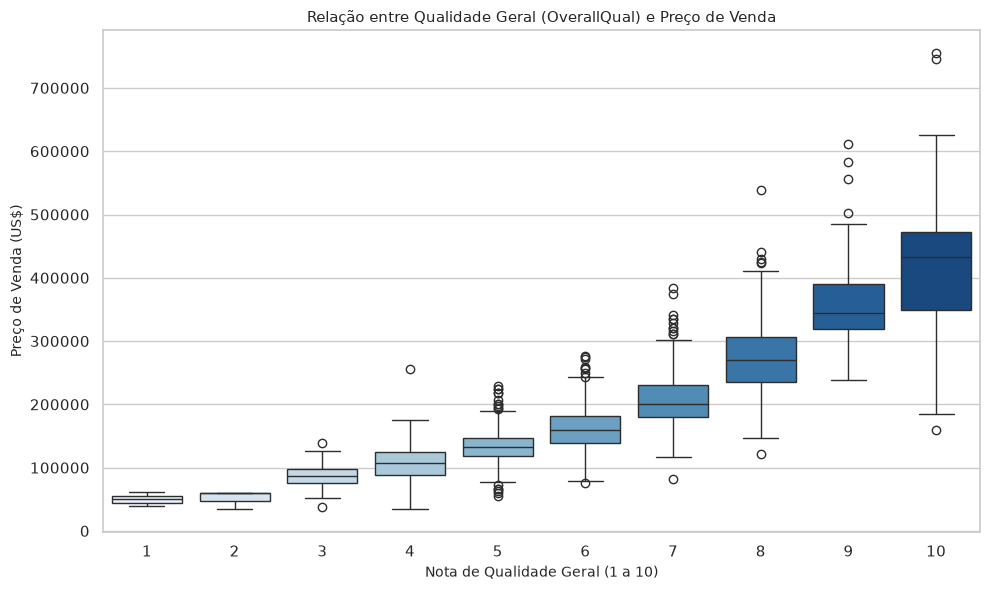

Tratamento de ausência estrutural:
  - Coluna Alley        | Nulos originais: 1369 -> Preenchido com 'NoAlley'
  - Coluna PoolQC       | Nulos originais: 1453 -> Preenchido com 'NoPool'
  - Coluna Fence        | Nulos originais: 1179 -> Preenchido com 'NoFence'
  - Coluna FireplaceQu  | Nulos originais:  690 -> Preenchido com 'NoFireplace'
  - Coluna GarageType   | Nulos originais:   81 -> Preenchido com 'NoGarage'


In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", palette="Blues")
plt.title("Relação entre Qualidade Geral (OverallQual) e Preço de Venda")
plt.xlabel("Nota de Qualidade Geral (1 a 10)")
plt.ylabel("Preço de Venda (US$)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_overall_qual_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

# Tratamento de ausências estruturais onde NA representa inexistência física
structural_missing = {
    "Alley": "NoAlley",
    "PoolQC": "NoPool",
    "Fence": "NoFence",
    "FireplaceQu": "NoFireplace",
    "GarageType": "NoGarage",
}

print("Tratamento de ausência estrutural:")
for col, fill_val in structural_missing.items():
    missing_before = df[col].isna().sum()
    df[col] = df[col].fillna(fill_val)
    print(f"  - Coluna {col:12s} | Nulos originais: {missing_before:4d} -> Preenchido com '{fill_val}'")

## 12. Codificação ordinal

Os números de 1 a 5 preservam a ordem das avaliações. O código 0 indica ausência de subsolo em `BsmtQual`. A escala compacta facilita cortes por árvores, mas modelos de distância ou lineares podem impor intervalos iguais entre categorias. One-Hot Encoding evita essa suposição, usando mais colunas.

## 13. Tratamento de ausências

Em `Alley`, `PoolQC`, `Fence`, `FireplaceQu` e `GarageType`, a documentação identifica a ausência como inexistência do recurso; o notebook usa uma categoria explícita. Para a floresta, outras categorias ausentes recebem um marcador e valores numéricos são preenchidos pela mediana. O CSV exportado conserva ausências em outras colunas. A causa de cada ausência remanescente não foi determinada.

## 14. Qualidade geral e preço

As medianas de preço aumentam de US$ 133.000 na nota 5 para US$ 200.141 na nota 7 e US$ 345.000 na nota 9. As distribuições se sobrepõem; a comparação não mede efeito causal de uma mudança de qualidade.

## 15. Seleção de atributos com Random Forest

A floresta usa todas as variáveis originais, exceto o identificador `Id`, e os atributos criados. As categorias são codificadas em indicadores; suas importâncias são somadas por coluna original. Valores numéricos ausentes são preenchidos pela mediana e categorias ausentes recebem um indicador próprio. O ajuste usa toda a amostra e descreve apenas este conjunto; não estima desempenho em dados novos.

In [12]:
# Cada coluna original mantém sua identidade ao agregar os indicadores categóricos
X_raw = df.drop(columns=["Id", "SalePrice"])
encoded, origins = [], []
for col in X_raw.columns:
    if pd.api.types.is_numeric_dtype(X_raw[col]):
        values = X_raw[col].fillna(X_raw[col].median()).to_frame()
    else:
        values = pd.get_dummies(X_raw[col].fillna("__ausente__"), prefix=col, dtype=int)
    encoded.append(values)
    origins.extend([col] * values.shape[1])
X_rf = pd.concat(encoded, axis=1)
rf_model = RandomForestRegressor(random_state=42, n_estimators=100, n_jobs=-1)
rf_model.fit(X_rf, df["SalePrice"])
importance_series = pd.Series(rf_model.feature_importances_).groupby(origins).sum().sort_values(ascending=False)
importance_df = pd.DataFrame({"Feature": importance_series.index, "Importance": importance_series.values, "Cumulative": importance_series.cumsum().values})
print(f"Preditores avaliados: {len(importance_series)}; colunas após codificação: {X_rf.shape[1]}")
importance_df.head(15).round(4)

Preditores avaliados: 85; colunas após codificação: 309


,Feature,Importance,Cumulative
0,TotalArea,0.4287,0.4287
1,OverallQual,0.3376,0.7663
2,2ndFlrSF,0.0273,0.7936
3,YearBuilt,0.0147,0.8083
4,BsmtFinSF1,0.0124,0.8207
5,HouseAge,0.0118,0.8325
6,LotArea,0.0108,0.8434
7,GrLivArea,0.0108,0.8541
8,GarageArea,0.0089,0.8630
9,KitchenQual_Num,0.0085,0.8716


## 16. Passo 15 — Importância dos preditores e ajuste da Análise de Componentes Principais (PCA)

Visualização gráfica das 15 variáveis mais relevantes e aplicação de PCA sobre os atributos contínuos padronizados com `StandardScaler` para redução dimensional para 2 componentes principais.

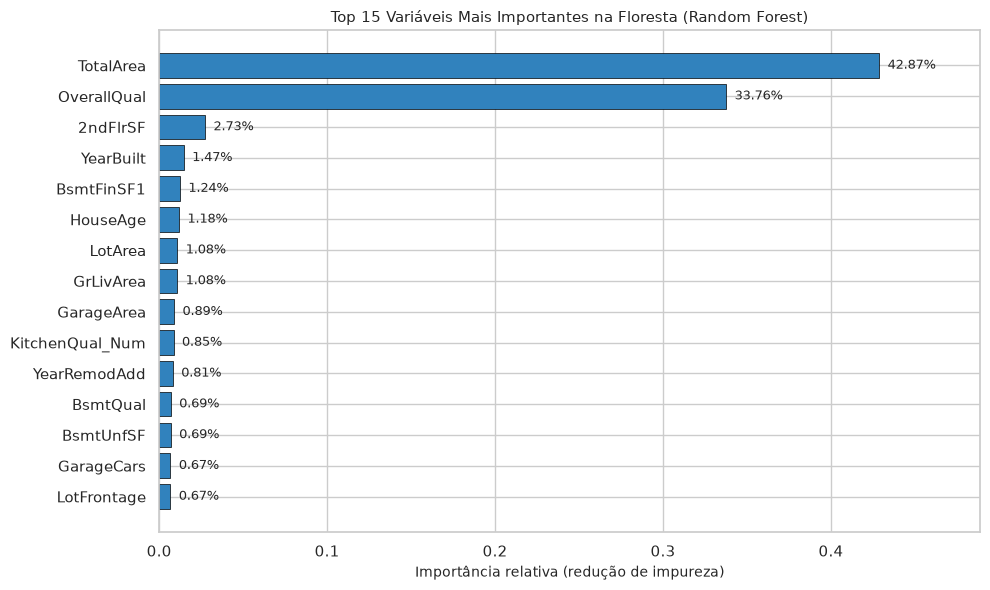

In [13]:
# Gráfico de barras horizontais do Top 15
plt.figure(figsize=(10, 6))
top_15_plot = importance_df.head(15).sort_values(by="Importance", ascending=True)
plt.barh(top_15_plot["Feature"], top_15_plot["Importance"], color="#3182bd", edgecolor="black", linewidth=0.5)
plt.xlabel("Importância relativa (redução de impureza)")
plt.title("Top 15 Variáveis Mais Importantes na Floresta (Random Forest)")
for i, v in enumerate(top_15_plot["Importance"]):
    plt.text(v + 0.005, i, f"{v*100:.2f}%", va="center", fontsize=9)
plt.xlim(0, top_15_plot["Importance"].max() + 0.06)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
# Preparação dos atributos contínuos para PCA
pca_features = [
    "TotalArea", "GrLivArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF",
    "GarageArea", "LotArea", "LotFrontage", "MasVnrArea", "BsmtFinSF1",
    "BsmtUnfSF", "HouseAge", "WoodDeckSF", "OpenPorchSF"
]

X_pca_raw = df[pca_features].copy()
X_pca_raw["LotFrontage"] = X_pca_raw["LotFrontage"].fillna(X_pca_raw["LotFrontage"].median())
X_pca_raw["MasVnrArea"] = X_pca_raw["MasVnrArea"].fillna(0)

# Padronização Z-score (média 0, desvio padrão 1)
scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca_raw)

# Ajuste do PCA com 2 componentes principais
pca_model = PCA(n_components=2, random_state=42)
pca_transformed = pca_model.fit_transform(X_pca_scaled)

df["PC1"] = pca_transformed[:, 0]
df["PC2"] = pca_transformed[:, 1]

evr = pca_model.explained_variance_ratio_
print(f"Variância explicada por PC1: {evr[0] * 100:.2f}%")
print(f"Variância explicada por PC2: {evr[1] * 100:.2f}%")
print(f"Variância acumulada nos dois primeiros componentes: {evr.sum() * 100:.2f}%")

Variância explicada por PC1: 35.79%
Variância explicada por PC2: 12.53%
Variância acumulada nos dois primeiros componentes: 48.32%


## 17. Passo 16 — Dispersão dos componentes principais colorida por qualidade

Projeção bidimensional das 1.460 residências no plano PC1 vs PC2, com coloração contínua baseada na nota de `OverallQual` para verificar o padrão de agrupamento e separabilidade geométrica.

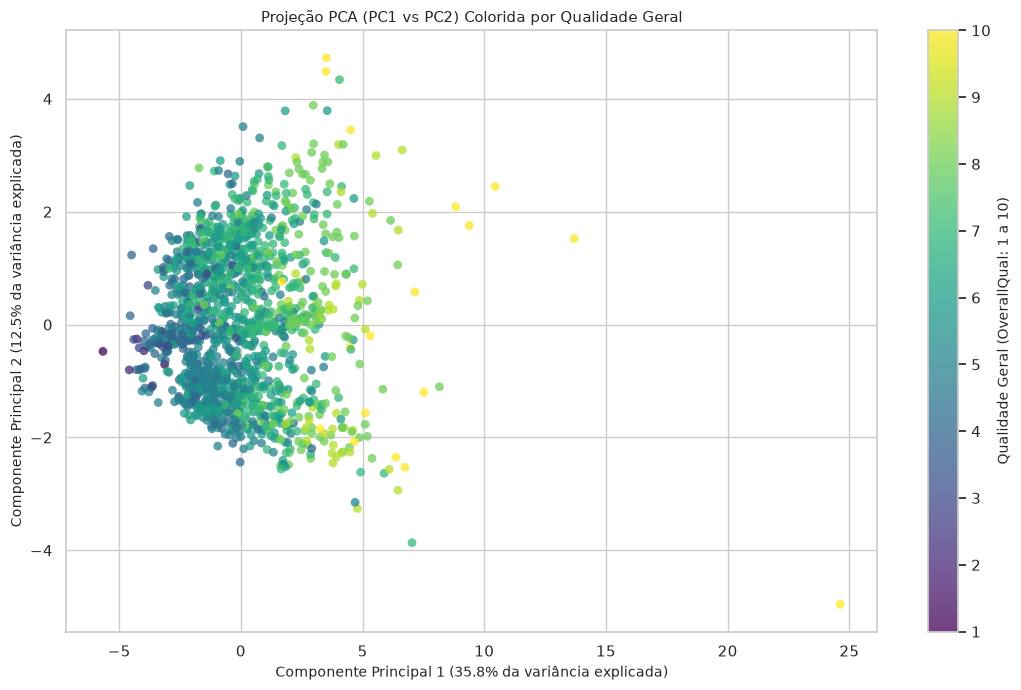

In [15]:
plt.figure(figsize=(11, 7))
scatter = plt.scatter(
    df["PC1"],
    df["PC2"],
    c=df["OverallQual"],
    cmap="viridis",
    alpha=0.75,
    edgecolors="none",
    s=40
)
cbar = plt.colorbar(scatter)
cbar.set_label("Qualidade Geral (OverallQual: 1 a 10)", fontsize=10)
plt.title("Projeção PCA (PC1 vs PC2) Colorida por Qualidade Geral")
plt.xlabel(f"Componente Principal 1 ({evr[0]*100:.1f}% da variância explicada)")
plt.ylabel(f"Componente Principal 2 ({evr[1]*100:.1f}% da variância explicada)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "house_prices_pca_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

## 18. Interpretação do ranking e do PCA

O ranking mede a redução de erro quadrático nas divisões da floresta ajustada à amostra. Variáveis correlacionadas podem dividir essa importância, e atributos com muitas categorias ou pontos de corte podem ser favorecidos. Por isso, os percentuais não medem efeito causal nem comprovam desempenho fora da amostra. Na amostra, `TotalArea` tem 42,87% da importância, `OverallQual` 33,76%, `HouseAge` 1,18% e `IsRemodeled` 0,05%. Essas parcelas dependem dos demais atributos presentes e não indicam retorno de uma intervenção.

O PCA resume os 14 atributos numéricos padronizados em duas combinações. Os percentuais impressos indicam a parte da variância retida; a projeção perde o restante e serve à exploração, não à previsão de preços.

## 19. Análise da dispersão no plano PCA

As cores mostram um gradiente de qualidade ao longo da projeção, com sobreposição entre notas. Os componentes resumem os atributos selecionados; sua direção e suas cargas dependem da amostra. O gráfico não demonstra grupos separados nem uma relação causal entre qualidade e preço.

## 20. Passo 19 — Exportação do dataset de atributos processados

Exportação do conjunto de dados transformado contendo as variáveis originais, os atributos sintéticos (`HouseAge`, `TotalArea`, `IsRemodeled`), as escalas ordinais numéricas (`ExterQual_Num`, `BsmtQual_Num`, `KitchenQual_Num`), o tratamento de ausências estruturais e os eixos de projeção `PC1` e `PC2` para `data/processed/house_prices_features.csv`.

O arquivo conserva valores ausentes nas colunas originais que não receberam tratamento explícito. Antes da modelagem, separe treino e teste e ajuste as transformações apenas no treino.

In [16]:
output_features_path = PROCESSED_DIR / "house_prices_features.csv"
df.to_csv(output_features_path, index=False)
print(f"Dataset processado exportado com sucesso em: {output_features_path.relative_to(PROJECT_ROOT)}")
print(f"Dimensões finais: {df.shape[0]} linhas x {df.shape[1]} colunas")

Dataset processado exportado com sucesso em: data/processed/house_prices_features.csv
Dimensões finais: 1460 linhas x 89 colunas


## 22. Conclusão

`TotalArea` apresenta correlação positiva com `SalePrice`, enquanto `HouseAge` apresenta correlação negativa. O ranking compara os atributos originais e criados na floresta ajustada à amostra. O PCA mostra um gradiente de qualidade, com sobreposição entre grupos. Esses resultados são associações exploratórias.

## 23. Recomendações

Para uma avaliação imobiliária, compare imóveis semelhantes considerando área, idade e qualidade. Antes de recomendar reformas ou estimar retorno financeiro, avalie custo, localização e efeito da intervenção com dados adequados. Para um modelo preditivo, separe treino e teste antes de ajustar imputação, codificação, seleção e PCA.

## 23. Passo 22 — Exportação das figuras em alta resolução e métricas consolidadas

Gravação das 6 figuras gráficas com resolução de 300 DPI e do arquivo de métricas em formato JSON em `reports/evidence/` para alimentar os relatórios técnicos e a suíte de testes de integridade.

In [17]:
metrics_path = EVIDENCE_DIR / "house_prices_metrics.json"

top_corr_dict = {col: round(float(val), 4) for col, val in corr_series.head(10).items()}
top_15_rf_dict = {row["Feature"]: round(float(row["Importance"]), 4) for _, row in importance_df.head(15).iterrows()}

house_prices_metrics = {
    "total_records": int(len(df)),
    "saleprice_mean": round(float(df["SalePrice"].mean()), 2),
    "saleprice_median": round(float(df["SalePrice"].median()), 2),
    "saleprice_std": round(float(df["SalePrice"].std()), 2),
    "saleprice_skew": round(float(df["SalePrice"].skew()), 4),
    "top_correlations": top_corr_dict,
    "top_15_features": top_15_rf_dict,
    "feature_importances": {col: float(val) for col, val in importance_series.items()},
    "pca_explained_variance_ratio": [round(float(v), 4) for v in evr],
    "processed_shape": list(df.shape),
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(house_prices_metrics, f, indent=2, ensure_ascii=False)

print(f"Métricas exportadas com sucesso em: {metrics_path.relative_to(PROJECT_ROOT)}\n")
print(json.dumps(house_prices_metrics, indent=2, ensure_ascii=False))

Métricas exportadas com sucesso em: reports/evidence/house_prices_metrics.json

{
  "total_records": 1460,
  "saleprice_mean": 180921.2,
  "saleprice_median": 163000.0,
  "saleprice_std": 79442.5,
  "saleprice_skew": 1.8829,
  "top_correlations": {
    "SalePrice": 1.0,
    "OverallQual": 0.791,
    "GrLivArea": 0.7086,
    "GarageCars": 0.6404,
    "GarageArea": 0.6234,
    "TotalBsmtSF": 0.6136,
    "1stFlrSF": 0.6059,
    "FullBath": 0.5607,
    "TotRmsAbvGrd": 0.5337,
    "YearBuilt": 0.5229
  },
  "top_15_features": {
    "TotalArea": 0.4287,
    "OverallQual": 0.3376,
    "2ndFlrSF": 0.0273,
    "YearBuilt": 0.0147,
    "BsmtFinSF1": 0.0124,
    "HouseAge": 0.0118,
    "LotArea": 0.0108,
    "GrLivArea": 0.0108,
    "GarageArea": 0.0089,
    "KitchenQual_Num": 0.0085,
    "YearRemodAdd": 0.0081,
    "BsmtQual": 0.0069,
    "BsmtUnfSF": 0.0069,
    "GarageCars": 0.0067,
    "LotFrontage": 0.0067
  },
  "feature_importances": {
    "TotalArea": 0.4287135426001553,
    "OverallQual"